# Deep Learning 7

## O mecanismo de atenção: Transformers e Vision Transformers

Link Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ftl-brazil-2026/ebook/blob/main/deep-learning/dl7_atencao.ipynb)

Na aula 6 vimos como as **convoluções** dominaram a visão computacional: filtros locais, empilhados em redes cada vez
mais profundas (ResNet) e em encoder-decoders (U-Net). Hoje vamos conhecer o mecanismo que está por trás de quase toda
a IA atual: a **atenção**.

**Roteiro**

1. **O mecanismo de atenção**: a intuição de *query*, *key* e *value*, e a atenção escrita do zero
2. **O bloco Transformer**: atenção + MLP + conexões residuais + normalização
3. **Vision Transformer (ViT)**: imagens como sequências de pedaços, e a atenção de um modelo de verdade (DINOv2)
4. **Um primeiro olhar no aprendizado auto-supervisionado**: o que um modelo aprende sem nenhum rótulo

Como na aula 6, cada arquitetura tem uma **ficha** 🗂️ com o ano, o tipo de treino, pontos fortes e limitações.

In [1]:
# no Google Colab, o PyTorch já vem instalado; o timm pode não vir
import sys
if "google.colab" in sys.modules:
    !pip install -q timm

In [2]:
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")     # saída mais limpa ao baixar do Hugging Face
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from skimage import data, io
from PIL import Image
import timm
from huggingface_hub import hf_hub_download

# cores e estilo dos gráficos (as mesmas das aulas de Machine Learning)
AZUL, LARANJA, VERDE, CINZA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110,
})

torch.manual_seed(42)

# imagens no padrão do ImageNet (o mesmo usado no pré-treino do DINOv2)
MEDIA = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
DESVIO = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
normaliza = lambda x: (x - MEDIA) / DESVIO

# o dataset LandCover.ai da aula 6 (já fica no cache do Hugging Face se você rodou aquela aula)
PASTA_LC = "data/landcoverai"
if not os.path.exists(PASTA_LC):
    caminho = hf_hub_download(repo_id="isaaccorley/landcoverai", filename="landcoverai100.zip", repo_type="dataset")
    zipfile.ZipFile(caminho).extractall(PASTA_LC)
NOMES_LC = ["fundo", "edificação", "floresta", "água", "estrada"]
CORES_LC = ["#d9d9d9", "#e34948", "#1baf7a", "#2a78d6", "#eda100"]
cmap_lc = ListedColormap(CORES_LC)
print(f"PyTorch {torch.__version__}, timm {timm.__version__}")

PyTorch 2.14.1, timm 1.0.30


# Parte 1 — O mecanismo de atenção

## 1.1 A intuição

Uma convolução (aula 6) olha só para a **vizinhança** de cada pixel. Para relacionar partes distantes da imagem (o olho
esquerdo com o direito, um rio com a ponte que o cruza) uma CNN precisa empilhar muitas camadas.

A **atenção** faz isso em **uma** camada: cada elemento (uma palavra, um pedaço da imagem) olha para **todos** os
outros e decide quanto cada um importa para ele. Cada elemento gera três vetores:

| Vetor | Pergunta | Analogia em uma biblioteca |
|---|---|---|
| **Query** $Q$ | "o que eu estou procurando?" | o que você digita na busca |
| **Key** $K$ | "o que eu ofereço?" | o título de cada livro |
| **Value** $V$ | "qual o meu conteúdo?" | o conteúdo do livro |

A semelhança entre a *query* de um elemento e a *key* de cada outro vira um **peso**, e a saída é a média dos *values*
ponderada por esses pesos:

$$\text{Atenção}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

## 1.2 Atenção do zero

entrada (6, 16) → Q, K, V (6, 8) → saída (6, 8)
igual ao F.scaled_dot_product_attention do PyTorch? True
cada linha dos pesos soma 1: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


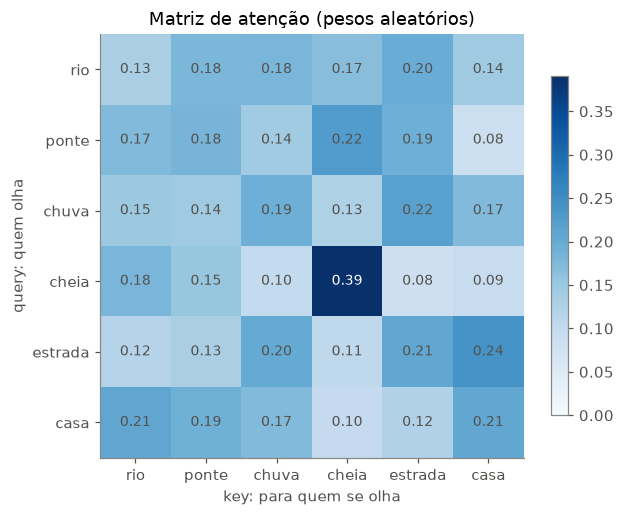

In [3]:
def atencao(Q, K, V):
    d = Q.shape[-1]
    pontuacoes = Q @ K.transpose(-2, -1) / d ** 0.5     # semelhança entre cada query e cada key
    pesos = pontuacoes.softmax(dim=-1)                   # cada linha soma 1
    return pesos @ V, pesos

torch.manual_seed(0)
tokens = ["rio", "ponte", "chuva", "cheia", "estrada", "casa"]
X_tok = torch.randn(len(tokens), 16)                     # 6 "tokens", cada um um vetor de 16 números
W_q, W_k, W_v = (nn.Linear(16, 8, bias=False) for _ in range(3))   # projeções aprendíveis

with torch.no_grad():
    Q, K, V = W_q(X_tok), W_k(X_tok), W_v(X_tok)
    saida, pesos = atencao(Q, K, V)
    saida_torch = F.scaled_dot_product_attention(Q[None], K[None], V[None])[0]
print(f"entrada {tuple(X_tok.shape)} → Q, K, V {tuple(Q.shape)} → saída {tuple(saida.shape)}")
print(f"igual ao F.scaled_dot_product_attention do PyTorch? {torch.allclose(saida, saida_torch, atol=1e-6)}")
print(f"cada linha dos pesos soma 1: {pesos.sum(dim=1).round(decimals=4).tolist()}")

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(pesos, cmap="Blues", vmin=0)
ax.set(xticks=range(6), xticklabels=tokens, yticks=range(6), yticklabels=tokens,
       xlabel="key: para quem se olha", ylabel="query: quem olha", title="Matriz de atenção (pesos aleatórios)")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{pesos[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if pesos[i, j] > 0.3 else TINTA)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Com projeções aleatórias os pesos não significam nada; **treinar** é justamente ajustar $W_q$, $W_k$ e $W_v$ para que
cada elemento preste atenção nos outros elementos **relevantes**.

Na prática usamos **várias cabeças** (*multi-head attention*): várias atenções em paralelo, cada uma com suas
projeções, que aprendem a procurar coisas diferentes. O PyTorch já tem a camada pronta:

In [4]:
mha = nn.MultiheadAttention(embed_dim=16, num_heads=4, batch_first=True)
saida, pesos_mha = mha(X_tok[None], X_tok[None], X_tok[None])      # autoatenção: Q, K e V vêm da mesma sequência
print(f"entrada (1, 6, 16) → saída {tuple(saida.shape)}, pesos {tuple(pesos_mha.shape)} (média das 4 cabeças)")

entrada (1, 6, 16) → saída (1, 6, 16), pesos (1, 6, 6) (média das 4 cabeças)


# Parte 2 — O bloco Transformer

A atenção sozinha não é um Transformer. Um **bloco Transformer** junta quatro peças, e três delas já conhecemos:

```
  x ──────────────┐                      x ─────────────┐
  │               │                      │              │
  LayerNorm       │                      LayerNorm      │
  │               │  conexão             │              │  conexão
  Multi-Head      │  residual            MLP            │  residual
  Attention       │  (ResNet!)           (Linear →      │
  │               │                       GELU →        │
  + ◄─────────────┘                       Linear)       │
  │                                      │              │
  └──────────── ► ───────────────────►   + ◄────────────┘
```

| Peça | Papel | Onde já vimos |
|---|---|---|
| **Multi-Head Attention** | cada token **troca informação** com todos os outros | Parte 1 |
| **MLP** (duas camadas lineares) | cada token **processa** a informação que recebeu, sozinho | aulas 1 a 4 |
| **Conexão residual** (`x + ...`) | o gradiente flui por dezenas de blocos | ResNet, aula 6 |
| **LayerNorm** | normaliza cada token (média 0, desvio 1), estabiliza o treino | parente do BatchNorm da ResNet |

Um modelo como o ViT ou um LLM é basicamente **dezenas desses blocos empilhados**.

In [5]:
class BlocoTransformer(nn.Module):
    def __init__(self, dim=16, cabecas=4, expansao=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.atencao = nn.MultiheadAttention(dim, cabecas, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, expansao * dim), nn.GELU(), nn.Linear(expansao * dim, dim))

    def forward(self, x):
        h = self.norm1(x)
        x = x + self.atencao(h, h, h)[0]        # 1. os tokens conversam entre si (+ residual)
        x = x + self.mlp(self.norm2(x))          # 2. cada token processa o que recebeu (+ residual)
        return x


bloco = BlocoTransformer()
x = X_tok[None]                                   # (1 sequência, 6 tokens, 16 números)
print(f"entrada {tuple(x.shape)} → saída {tuple(bloco(x).shape)}: o formato não muda, então dá para empilhar")

pronto = nn.TransformerEncoderLayer(d_model=16, nhead=4, dim_feedforward=64, batch_first=True, norm_first=True)
print(f"parâmetros: nosso bloco = {sum(p.numel() for p in bloco.parameters())}, "
      f"nn.TransformerEncoderLayer do PyTorch = {sum(p.numel() for p in pronto.parameters())}")

encoder = nn.Sequential(*[BlocoTransformer() for _ in range(6)])  # 6 blocos empilhados = um encoder Transformer
print(f"6 blocos empilhados: {tuple(encoder(x).shape)}, {sum(p.numel() for p in encoder.parameters()):,} parâmetros")

entrada (1, 6, 16) → saída (1, 6, 16): o formato não muda, então dá para empilhar
parâmetros: nosso bloco = 3280, nn.TransformerEncoderLayer do PyTorch = 3280
6 blocos empilhados: (1, 6, 16), 19,680 parâmetros


### A atenção não sabe a ordem dos tokens

Um detalhe importante: a atenção compara **todos com todos**, sem olhar a posição. Se embaralharmos os tokens da
entrada, a saída sai **embaralhada do mesmo jeito**, com os mesmos valores. Para o bloco, "o rio transbordou após a
chuva" e "a chuva transbordou após o rio" seriam a mesma coisa!

In [6]:
torch.manual_seed(0)
ordem = torch.randperm(6)
with torch.no_grad():
    saida_normal = bloco(X_tok[None])[0]
    saida_embaralhada = bloco(X_tok[ordem][None])[0]
print(f"nova ordem dos tokens: {ordem.tolist()}")
print(f"a saída embaralhada é a saída normal na nova ordem? {torch.allclose(saida_embaralhada, saida_normal[ordem], atol=1e-5)}")

nova ordem dos tokens: [2, 5, 3, 0, 1, 4]
a saída embaralhada é a saída normal na nova ordem? True


Por isso todo Transformer **soma uma informação de posição** a cada token antes do primeiro bloco: um vetor diferente
para a posição 1, 2, 3... (*positional embedding*), que pode ser fixo (senos e cossenos, no artigo original) ou
aprendido (no ViT). Com isso, o mesmo token em posições diferentes passa a ter representações diferentes.

> ### 🗂️ Ficha: Transformer
>
> | | |
> |---|---|
> | **Ano** | 2017 (Vaswani et al., Google, artigo *Attention Is All You Need*) |
> | **Antiga ou nova?** | **Recente** em termos históricos e a base da IA atual (GPT, Claude, Gemini, BERT, ViT) |
> | **Tipo de treino** | originalmente **supervisionado** (tradução de textos com pares de frases); hoje quase sempre **auto-supervisionado** em grandes volumes de texto (prever a próxima palavra ou palavras mascaradas) |
> | **Por que é importante** | substituiu as redes recorrentes (LSTM) e a convolução pela **atenção**: cada elemento se relaciona com todos os outros em uma única camada, e o cálculo é **paralelo**, ideal para GPUs |
> | **Pontos fortes** | contexto **global**; escala muito bem com dados e com tamanho do modelo; a mesma arquitetura serve para texto, imagens, áudio e séries temporais. Cada bloco usa **conexões residuais** (a ideia da ResNet!) e *LayerNorm* |
> | **Limitações** | o custo da atenção cresce com o **quadrado** do número de elementos (imagens grandes ficam caras); precisa de **muitos dados** porque tem pouco conhecimento embutido sobre a estrutura do problema |
> | **Ainda é usada?** | é **a** arquitetura dominante hoje |

# Parte 3 — Vision Transformer (ViT)

## 3.1 Uma imagem é uma sequência de pedaços

Como aplicar atenção a uma imagem? Atenção entre **todos os pixels** seria cara demais (uma imagem 224 × 224 tem 50 mil
pixels, então 2,5 bilhões de pares). O ViT corta a imagem em **pedaços** (*patches*), por exemplo de 16 × 16 pixels, e
trata cada pedaço como uma "palavra":

1. a imagem 224 × 224 vira uma grade de 14 × 14 = **196 patches**;
2. cada patch é achatado e projetado em um vetor (um *token*);
3. somamos uma **posição** a cada token (a atenção sozinha não sabe onde cada patch estava);
4. adicionamos um token especial **[CLS]**, que no fim resume a imagem inteira;
5. a sequência passa por vários blocos Transformer.

imagem (3, 224, 224) → 196 patches de (3, 16, 16) → tokens de 768 números


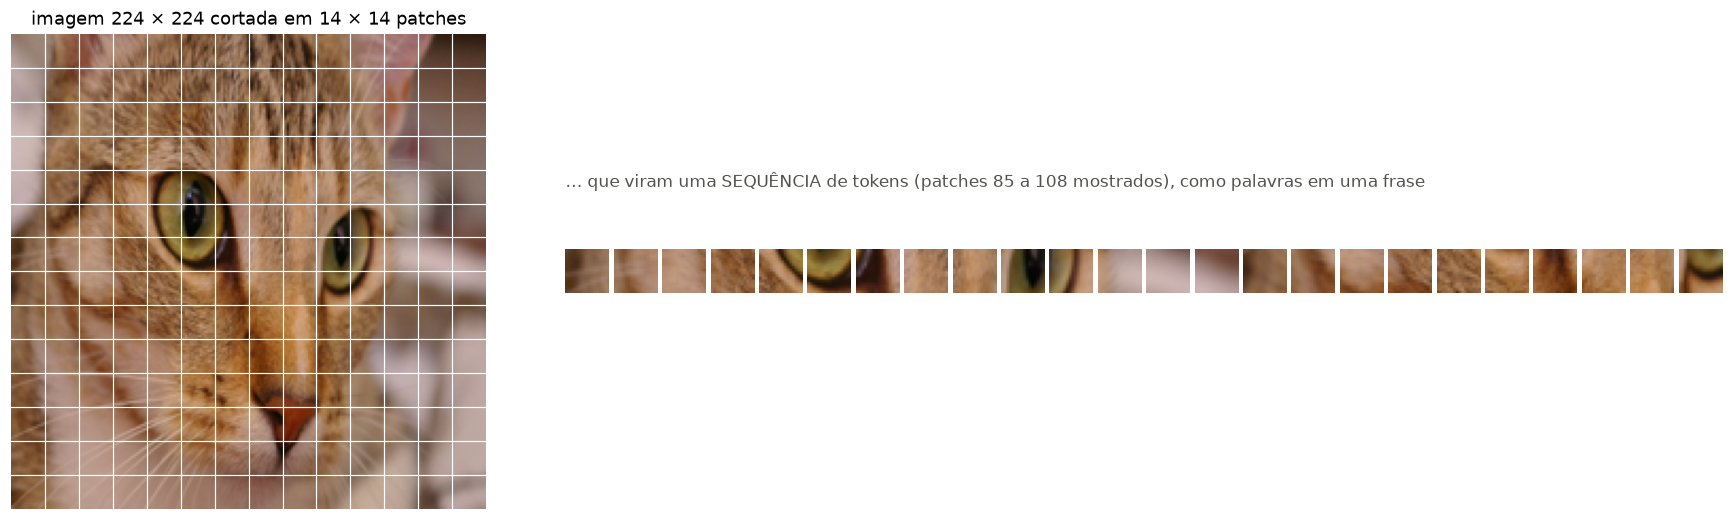

In [7]:
gato = transforms.functional.to_tensor(Image.fromarray(data.chelsea()).resize((224, 224)))
P = 16
patches = gato.unfold(1, P, P).unfold(2, P, P)                       # (3, 14, 14, 16, 16)
patches = patches.permute(1, 2, 0, 3, 4).reshape(-1, 3, P, P)        # (196, 3, 16, 16): uma sequência de 196 patches
print(f"imagem {tuple(gato.shape)} → {patches.shape[0]} patches de {tuple(patches.shape[1:])} → tokens de {3 * P * P} números")

fig = plt.figure(figsize=(16, 4.8))
ax = fig.add_axes([0.0, 0.05, 0.3, 0.9])
ax.imshow(gato.permute(1, 2, 0))
for k in range(1, 14):
    ax.axhline(k * P - 0.5, color="white", lw=0.8)
    ax.axvline(k * P - 0.5, color="white", lw=0.8)
ax.set_title("imagem 224 × 224 cortada em 14 × 14 patches")
ax.axis("off")
for k in range(24):
    ax = fig.add_axes([0.33 + k * 0.0275, 0.42, 0.025, 0.16])
    ax.imshow(patches[k + 84].permute(1, 2, 0))
    ax.axis("off")
fig.text(0.33, 0.66, "… que viram uma SEQUÊNCIA de tokens (patches 85 a 108 mostrados), como palavras em uma frase",
         color=TINTA, fontsize=11)
plt.show()

> ### 🗂️ Ficha: Vision Transformer (ViT)
>
> | | |
> |---|---|
> | **Ano** | 2020 (Dosovitskiy et al., Google) |
> | **Antiga ou nova?** | **Recente** |
> | **Tipo de treino** | no artigo original, **supervisionado** em datasets gigantes (JFT-300M, 300 milhões de imagens); hoje os melhores ViTs são treinados de forma **auto-supervisionada** (Parte 5) |
> | **Por que é importante** | mostrou que **não é preciso convolução** para visão: um Transformer puro sobre patches iguala ou supera as CNNs, e unificou visão e linguagem na mesma arquitetura (base dos modelos multimodais) |
> | **Pontos fortes** | atenção **global** desde a primeira camada; escala muito bem com dados; é a base dos **modelos de fundação** de visão e de observação da Terra |
> | **Limitações** | com **poucos dados** costuma perder para CNNs (não tem o viés de vizinhança da convolução embutido); custo quadrático no número de patches; resolução limitada pelo tamanho do patch |
> | **Ainda é usada?** | **sim**, é a base de DINOv2, SAM, CLIP, Prithvi e muitos outros |

## 3.2 Vendo a atenção de um ViT de verdade

Vamos abrir um ViT treinado: o **DINOv2** (ViT-S/14, versão com *registers*), baixado do Hub. Interceptamos a entrada
da última camada de atenção e calculamos os pesos $\text{softmax}(QK^\top/\sqrt{d})$, como na seção 1.2.

Duas perguntas:

1. Se escolhermos o patch de **um olho** do gato, para onde ele presta atenção?
2. Para onde olha cada uma das 6 **cabeças** do token [CLS]?

> Sobre os *registers*: ViTs grandes tendem a "esconder" informação global em alguns patches do fundo, o que deixa os
> mapas de atenção ruidosos. A versão com *registers* (Darcet et al., 2023) adiciona 4 tokens extras para esse papel,
> e os mapas ficam limpos.

In [8]:
inicio = time.time()
dino = timm.create_model("hf-hub:timm/vit_small_patch14_reg4_dinov2.lvd142m", pretrained=True, img_size=448).eval()
N_PREFIXO = dino.num_prefix_tokens                       # 1 [CLS] + 4 registers
LADO = 448 // 14                                         # 32 × 32 patches
print(f"DINOv2 ViT-S/14 carregado em {time.time() - inicio:.0f} s: {sum(p.numel() for p in dino.parameters()) / 1e6:.0f} M parâmetros, "
      f"{len(dino.blocks)} blocos, {dino.blocks[-1].attn.num_heads} cabeças, {N_PREFIXO} tokens especiais")

def prepara(img, lado=448):
    x = transforms.functional.to_tensor(Image.fromarray(img).resize((lado, lado), Image.BICUBIC))
    return normaliza(x)[None]

capturado = {}
dino.blocks[-1].attn.register_forward_hook(lambda modulo, entrada, saida: capturado.__setitem__("x", entrada[0]))

@torch.no_grad()
def atencao_ultima_camada(img):
    """Devolve as features dos patches e os pesos de atenção da última camada: (cabeças, tokens, tokens)."""
    feats = dino.forward_features(prepara(img))
    a, x = dino.blocks[-1].attn, capturado["x"]
    B, N, C = x.shape
    qkv = a.qkv(x).reshape(B, N, 3, a.num_heads, C // a.num_heads).permute(2, 0, 3, 1, 4)
    q, k = a.q_norm(qkv[0]), a.k_norm(qkv[1])
    pesos = (q @ k.transpose(-2, -1) * a.scale).softmax(dim=-1)
    return feats[0, N_PREFIXO:], pesos[0]

img_gato = data.chelsea()
feats_gato, att_gato = atencao_ultima_camada(img_gato)
print(f"features dos patches: {tuple(feats_gato.shape)}   pesos de atenção: {tuple(att_gato.shape)}")

DINOv2 ViT-S/14 carregado em 1 s: 22 M parâmetros, 12 blocos, 6 cabeças, 5 tokens especiais
features dos patches: (1024, 384)   pesos de atenção: (6, 1029, 1029)


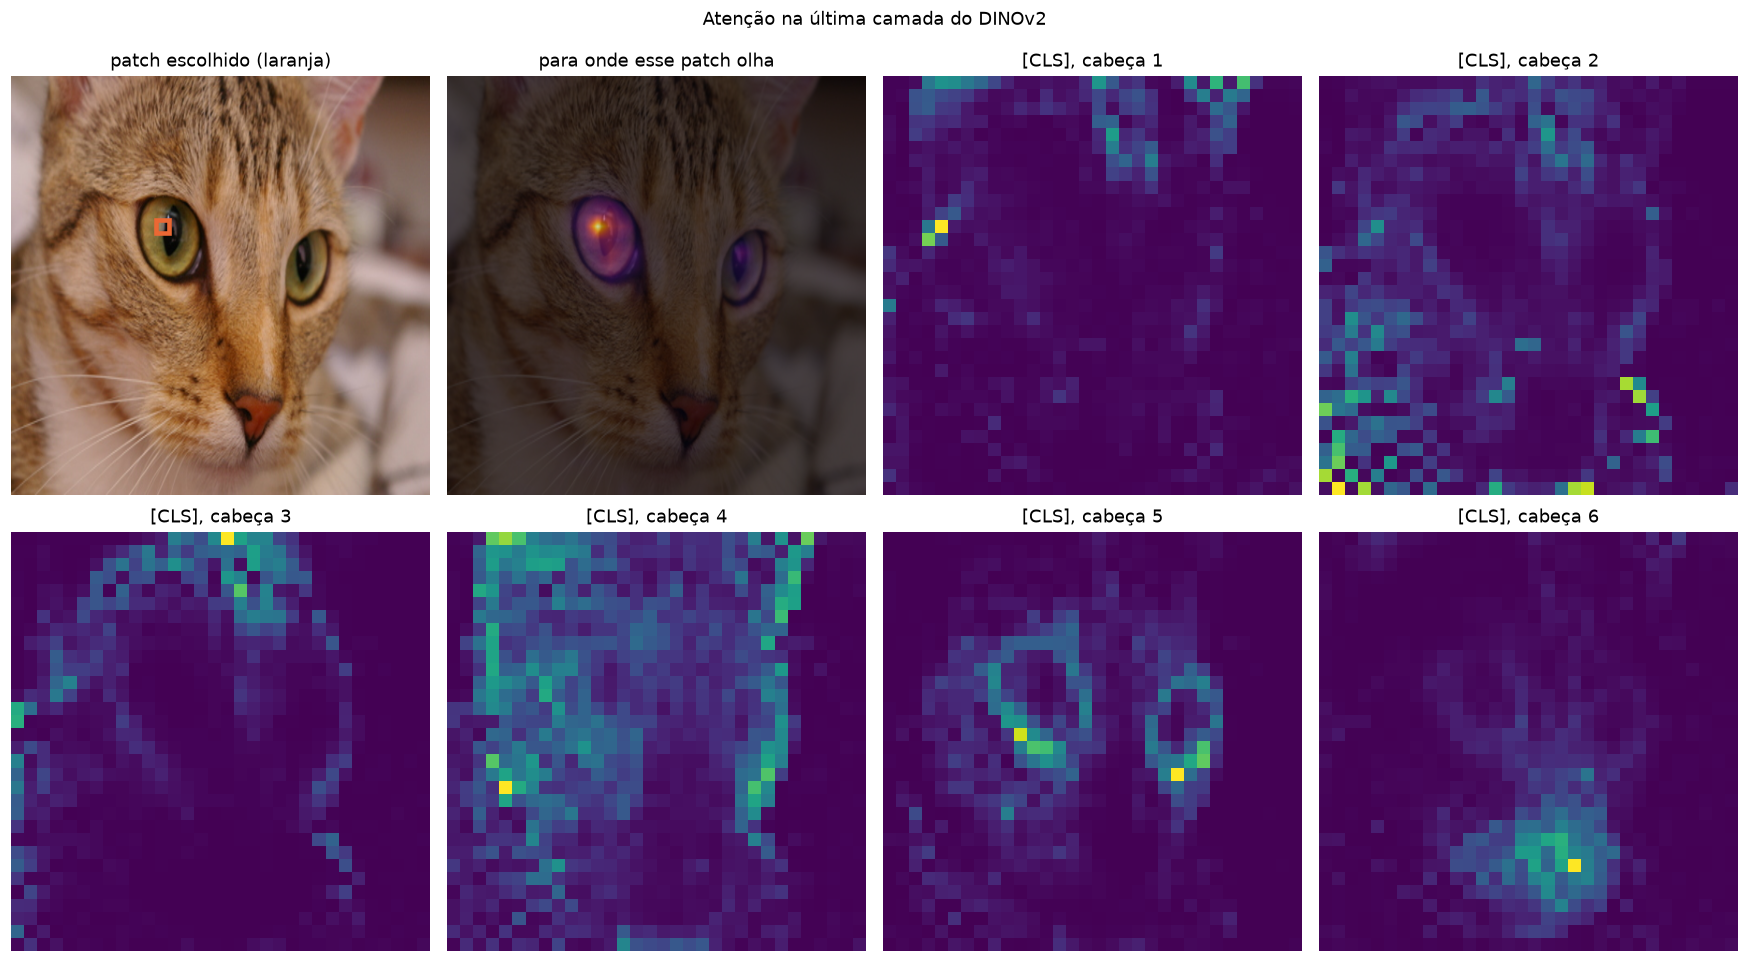

In [9]:
gato_448 = np.array(Image.fromarray(img_gato).resize((448, 448)))
linha_olho, coluna_olho = 11, 11                                     # patch sobre o olho esquerdo
indice_olho = N_PREFIXO + linha_olho * LADO + coluna_olho
mapa_olho = att_gato[:, indice_olho, N_PREFIXO:].mean(0).reshape(LADO, LADO)
mapas_cls = att_gato[:, 0, N_PREFIXO:].reshape(-1, LADO, LADO)       # atenção do [CLS] em cada cabeça

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes[0, 0].imshow(gato_448)
axes[0, 0].add_patch(Rectangle((coluna_olho * 14, linha_olho * 14), 14, 14, fill=False, edgecolor=LARANJA, lw=3))
axes[0, 0].set_title("patch escolhido (laranja)")
axes[0, 1].imshow(gato_448)
axes[0, 1].imshow(np.array(Image.fromarray(mapa_olho.numpy()).resize((448, 448), Image.BILINEAR)), cmap="inferno", alpha=0.65)
axes[0, 1].set_title("para onde esse patch olha")
for h in range(6):
    ax = axes.flat[2 + h]
    ax.imshow(mapas_cls[h], cmap="viridis")
    ax.set_title(f"[CLS], cabeça {h + 1}")
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Atenção na última camada do DINOv2", y=0.99)
plt.tight_layout()
plt.show()

**Leitura:** o patch de um olho presta atenção principalmente **no outro olho**, que está do outro lado da imagem.
Uma convolução 3 × 3 precisaria de muitas camadas para relacionar duas regiões tão distantes; a atenção faz isso em
uma operação. Cada cabeça do [CLS] se especializou em algo diferente: contornos, olhos, orelhas, regiões do fundo.

Ninguém disse ao modelo o que é um olho: **o DINOv2 nunca viu um rótulo**. Ele foi treinado de forma
auto-supervisionada, o assunto da última parte.

| | CNN (ResNet) | Transformer (ViT) |
|---|---|---|
| Operação básica | convolução (filtro local) | atenção (todos com todos) |
| Contexto | **local**, cresce com a profundidade | **global** desde a 1ª camada |
| Conhecimento embutido | vizinhança e translação (bom com poucos dados) | quase nenhum (precisa de muitos dados) |
| Custo | linear no nº de pixels | quadrático no nº de patches |
| Melhor quando | poucos dados, imagens grandes, tempo real | muitos dados, pré-treino em larga escala |

# Parte 4 — Um primeiro olhar no aprendizado auto-supervisionado

## 4.1 O gargalo dos rótulos

Tudo o que treinamos até aqui foi **supervisionado**: alguém rotulou cada imagem (ou cada pixel). Rótulos são caros,
lentos e, em observação da Terra, raros: existem **petabytes** de imagens de satélite, mas pouquíssimas máscaras de
uso do solo.

O **aprendizado auto-supervisionado** (*self-supervised learning*, SSL) cria a supervisão **a partir dos próprios
dados**, com uma tarefa "de pretexto":

| Família | Tarefa de pretexto | Exemplos |
|---|---|---|
| **Modelagem mascarada** | esconder ~75% dos patches e reconstruí-los | MAE (2021), SatMAE (2022), Prithvi (2023) |
| **Contrastiva** | duas versões aumentadas da mesma imagem devem ter representações parecidas, e imagens diferentes, distantes | SimCLR, MoCo (2020), SSL4EO-S12 (2022) |
| **Autodestilação** | um "aluno" aprende a imitar um "professor" que vê outra versão da imagem | DINO (2021), DINOv2 (2023), DINOv3 (2025) |

Depois desse **pré-treino** em milhões de imagens sem rótulo, o modelo vira um **modelo de fundação**: com poucas
imagens rotuladas, ele é adaptado (*fine-tuning*) para tarefas específicas, exatamente como fizemos com a ResNet-50
na U-Net da aula 6.

> ### 🗂️ Ficha: Modelos auto-supervisionados (MAE, DINO, DINOv2)
>
> | | |
> |---|---|
> | **Ano** | 2020–2021 (SimCLR, MoCo, MAE, DINO) e 2023 (DINOv2); continuam evoluindo rápido (DINOv3 em 2025) |
> | **Antiga ou nova?** | **Nova geração**: a fronteira atual da área |
> | **Tipo de treino** | **auto-supervisionado**: milhões ou bilhões de imagens **sem rótulos** (o DINOv2 usou 142 milhões de imagens selecionadas); depois, ajuste supervisionado com poucos rótulos |
> | **Por que é importante** | quebra a dependência de rótulos; as representações aprendidas são tão gerais que servem para classificação, segmentação, profundidade e busca **sem retreinar o backbone** |
> | **Pontos fortes** | aproveita dados não rotulados abundantes (perfeito para satélites); representações ricas e transferíveis; poucos rótulos para adaptar a novas tarefas |
> | **Limitações** | o pré-treino exige **muita computação** (centenas de GPUs); modelos grandes; é preciso escolher bem os dados e as tarefas de pretexto; o domínio importa (um modelo de fotos não é ideal para radar) |
> | **Ainda é usada?** | é **o** caminho dos modelos de fundação atuais, inclusive em observação da Terra |

## 4.2 O que um modelo auto-supervisionado aprende sem rótulos

Pegamos as **features** que o DINOv2 produz para cada patch (vetores de 384 números) e as comprimimos em **3 números**
com PCA, usados como cores RGB. Patches com features parecidas ficam com cores parecidas. Também agrupamos as features
com **K-means** (a técnica da aula de aprendizado não supervisionado) em 5 grupos.

Ninguém disse ao modelo o que é um olho, uma floresta ou um telhado.

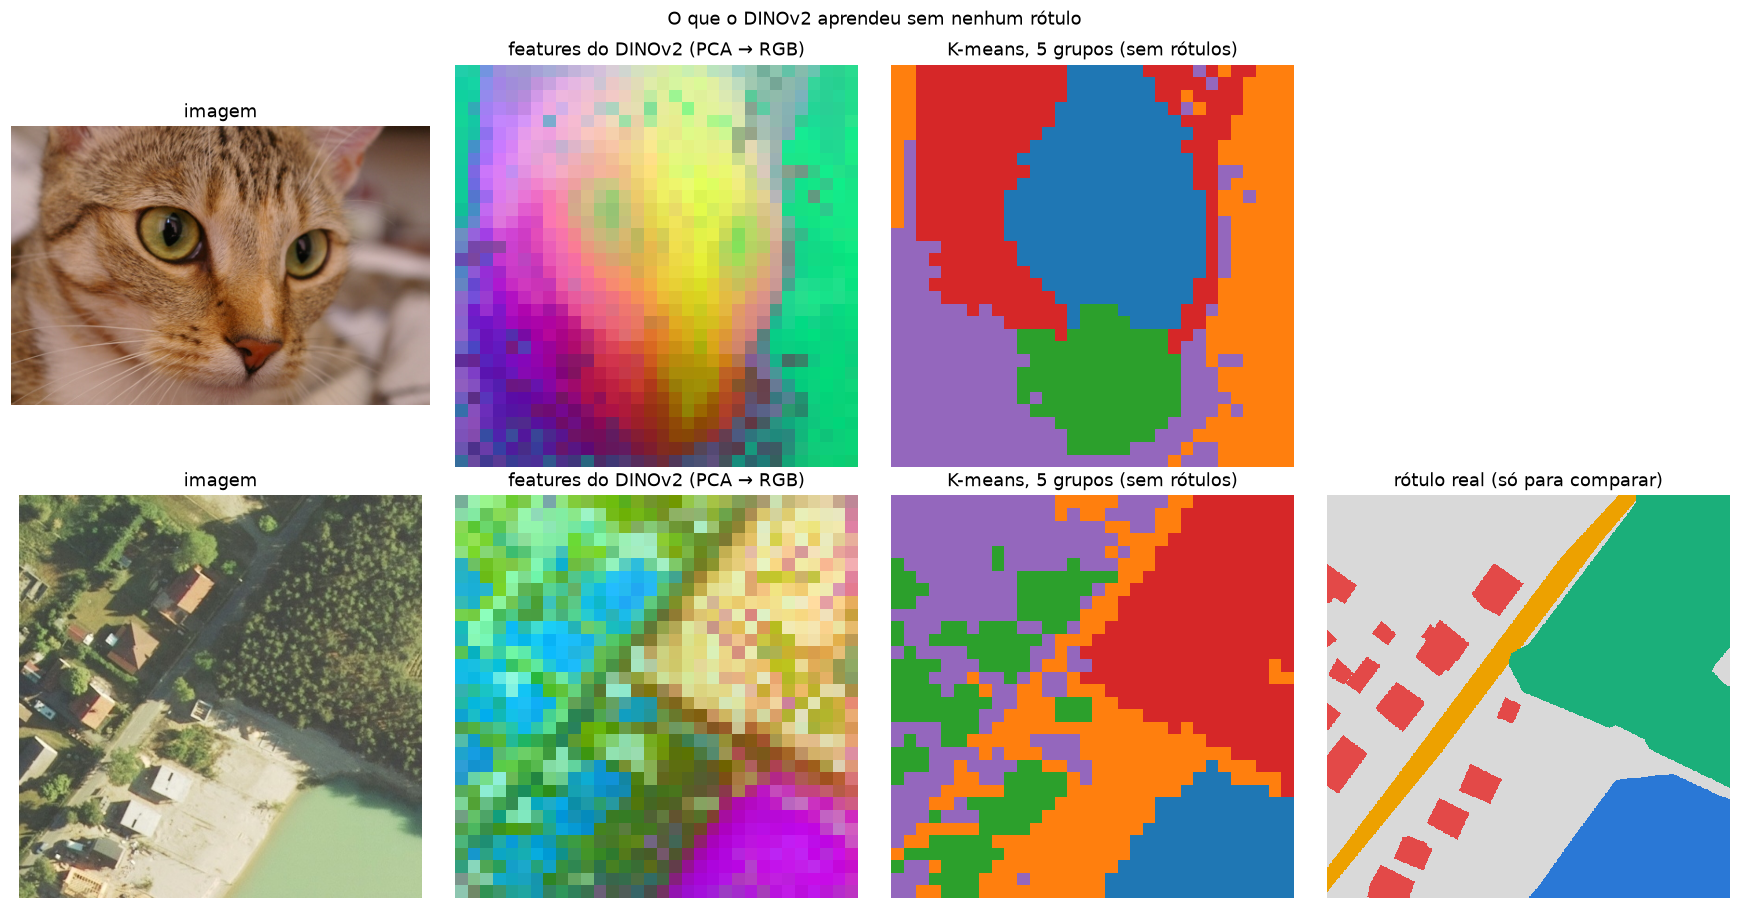

In [10]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

def pca_rgb(feats):
    rgb = PCA(n_components=3).fit_transform(feats.numpy())
    rgb = (rgb - rgb.min(0)) / (rgb.max(0) - rgb.min(0))
    return rgb.reshape(LADO, LADO, 3)

ID_AEREO = "M-33-20-D-d-3-3_247"                      # recorte com as 5 classes
img_aerea = io.imread(f"{PASTA_LC}/output/{ID_AEREO}.jpg")
mascara_aerea = io.imread(f"{PASTA_LC}/output/{ID_AEREO}_m.png")[..., 0]
feats_aereo, _ = atencao_ultima_camada(img_aerea)

fig, axes = plt.subplots(2, 4, figsize=(16, 8.3))
for linha, (img, feats, ref, titulo_ref) in enumerate([
        (img_gato, feats_gato, None, None),
        (img_aerea, feats_aereo, mascara_aerea, "rótulo real (só para comparar)")]):
    grupos = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(feats.numpy()).reshape(LADO, LADO)
    axes[linha, 0].imshow(img); axes[linha, 0].set_title("imagem")
    axes[linha, 1].imshow(pca_rgb(feats)); axes[linha, 1].set_title("features do DINOv2 (PCA → RGB)")
    axes[linha, 2].imshow(grupos, cmap="tab10", vmin=0, vmax=9, interpolation="nearest"); axes[linha, 2].set_title("K-means, 5 grupos (sem rótulos)")
    if ref is not None:
        axes[linha, 3].imshow(ref, cmap=cmap_lc, vmin=0, vmax=4, interpolation="nearest"); axes[linha, 3].set_title(titulo_ref)
    else:
        axes[linha, 3].axis("off")
    for ax in axes[linha, :3]:
        ax.axis("off")
axes[1, 3].axis("off")
plt.suptitle("O que o DINOv2 aprendeu sem nenhum rótulo", y=0.99)
plt.tight_layout()
plt.show()

**Leitura:** no gato, as features separam olhos, nariz e boca, pelo e fundo. Na imagem aérea, **floresta**, **água**
e a **área com casas e quintais** formam grupos diferentes, com fronteiras muito próximas das do rótulo real, e a
estrada aparece como uma faixa entre elas. O DINOv2 nem foi treinado com imagens aéreas, e o K-means não sabe os nomes
das classes (as cores dos grupos não correspondem às do rótulo). Mesmo assim, é quase uma segmentação sem um único rótulo.

## 4.3 Modelos de fundação para observação da Terra

A mesma ideia está sendo aplicada a imagens de satélite, com modelos disponíveis no Hugging Face:

| Modelo | Quem | Ano | Pré-treino | No Hub |
|---|---|---|---|---|
| **Prithvi-EO** | NASA e IBM | 2023 / 2024 | autoencoder mascarado (MAE) em séries temporais do Harmonized Landsat Sentinel-2 | `ibm-nasa-geospatial/Prithvi-EO-2.0-300M` |
| **SSL4EO-S12** | TU Munich / DLR | 2022 | contrastivo e MAE em Sentinel-1 e Sentinel-2 | `wangyi111/SSL4EO-S12` |
| **Clay** | Clay (organização sem fins lucrativos) | 2024 | MAE em vários sensores e resoluções | `made-with-clay/Clay` |
| **DOFA** | TU Munich e parceiros | 2024 | um único modelo para sensores com número de bandas diferente | `earthflow/DOFA` |
| **DINOv3 (satélite)** | Meta | 2025 | autodestilação em ~493 milhões de imagens de satélite | `facebook/dinov3-vitl16-pretrain-sat493m` |

**Na próxima aula** vamos entender como esses modelos são treinados (tarefas de pretexto, *masking*, autodestilação) e
como adaptá-los a um problema real com poucos rótulos.

# Resumo

| Conceito | Ideia-chave |
|---|---|
| **Atenção** | cada elemento olha para **todos** os outros, com pesos $\text{softmax}(QK^\top/\sqrt{d})$ |
| **Multi-head** | várias atenções em paralelo, cada uma procurando relações diferentes |
| **Bloco Transformer** | atenção + MLP, cada um com conexão residual e LayerNorm; dezenas de blocos empilhados |
| **Posição** | a atenção ignora a ordem; por isso somamos *positional embeddings* aos tokens |
| **ViT** | a imagem vira uma sequência de patches; atenção global desde a primeira camada |
| **Auto-supervisionado** | aprender representações **sem rótulos** (MAE, DINO) e depois adaptar com poucos rótulos |

| Arquitetura | Ano | Era | Tipo de treino | Ponto forte | Ponto fraco |
|---|---|---|---|---|---|
| Transformer | 2017 | atual | supervisionado → auto-supervisionado | contexto global, escala com dados | custo quadrático, precisa de muitos dados |
| ViT | 2020 | atual | supervisionado → auto-supervisionado | atenção global em imagens | fraco com poucos dados |
| DINOv2, MAE, Prithvi | 2021–2025 | nova geração | **auto-supervisionado** | representações gerais sem rótulos | pré-treino muito caro |

### Exercícios

1. Na seção 1.2, troque a divisão por $\sqrt{d}$ por uma divisão por 1. O que acontece com os pesos de atenção? (Dica:
   olhe o quanto cada linha fica "concentrada" em um único token.)
2. No `BlocoTransformer`, remova as duas conexões residuais e empilhe 12 blocos. A saída continua com valores razoáveis?
3. Some um vetor de posição aleatório (`torch.randn(6, 16)`) a `X_tok` e repita o teste de embaralhar os tokens. A saída
   embaralhada ainda é igual à normal reordenada? Por quê?
4. Na seção 3.2, mude o patch escolhido (por exemplo, para o nariz). Para onde ele olha agora?
5. Na seção 4.2, troque o número de grupos do K-means. Com quantos grupos a imagem aérea fica mais parecida com o rótulo real?